# Содержание

Нажмите на любой пункт ниже, чтобы мгновенно перейти к нужному разделу.

* [0. Настройки и константы](#0-настройки-и-константы)
* [1. Работа с фактом](#1-работа-с-фактом)
    * [1.1. Обработка факта](#11-обработка-факта)
    * [1.2. Анализ факта](#12-анализ-факта)
    * [1.3. Создание таблиц для каждого бюджетодержателя](#13-создание-таблиц-для-каждого-бюджетодержателя)
    * [1.4. Сбор пояснений от бюджетодержателей](#14-сбор-пояснений-от-бюджетодержателей)
* [2. Работа с прогнозом](#2-работа-с-прогнозом)
    * [2.1. Обновление прогноза](#21-обновление-прогноза)
    * [2.2. Анализ прогноза](#22-анализ-прогноза)

### 0. Настройки и константы

In [51]:
import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from openpyxl import load_workbook
from openpyxl.styles import PatternFill, Font, Alignment, Protection
from openpyxl.utils import get_column_letter
from openpyxl.drawing.image import Image as XLImage



# 1. ВЫБОР МЕСЯЦА 
ACTUAL_MONTH = "март" ## менять только эту строчку
ACTUAL_MONTH = ACTUAL_MONTH.strip().lower()

month_order = {
    "январь": 1, "февраль": 2, "март": 3, "апрель": 4, "май": 5, "июнь": 6,
    "июль": 7, "август": 8, "сентябрь": 9, "октябрь": 10, "ноябрь": 11, "декабрь": 12
}
all_months = list(month_order.keys())
if ACTUAL_MONTH not in month_order:
    raise ValueError(f"Ошибка: Месяц '{ACTUAL_MONTH}' написан неверно.")

# 2. ВЫЧИСЛЕНИЕ ПЕРИОДОВ 
current_month_num = month_order[ACTUAL_MONTH]
# Список закрытых месяцев (включая текущий)
closed_months = all_months[:current_month_num]
# Список будущих месяцев (без текущего)
future_months = all_months[current_month_num:]
# Предыдущий месяц (если это январь, возвращает None)
prev_month = all_months[current_month_num - 2] if current_month_num > 1 else None

# 3. НАСТРОЙКА ПУТЕЙ
# --- ИСХОДНЫЕ ДАННЫЕ ---
PATH_BUDGET = os.path.join('Исходные данные', 'бюджет.xlsx')
PATH_NEW_ACTUALS = os.path.join('Исходные данные', 'факт', f'SAP_факт_{ACTUAL_MONTH}.xlsx')

# --- РЕЗУЛЬТАТЫ ---
PATH_ACTUALS_TOTAL = os.path.join('Результат', 'факт_сводный.xlsx')

# --- АНАЛИТИКА ПО ФАКТУ (готовим к 3-му числу) ---
DIR_ANALYSIS_FACT = os.path.join('Результат', 'Аналитика', 'факт', ACTUAL_MONTH)
# Отчет с таблицами (план-факт, бюджет vs факт)
OUTPUT_FILE_FACT = os.path.join(DIR_ANALYSIS_FACT, f'Отчет_Факт_{ACTUAL_MONTH.capitalize()}.xlsx')

# --- АНАЛИТИКА ПО ПРОГНОЗУ (готовим к 15-му числу) ---
DIR_ANALYSIS_FORECAST = os.path.join('Результат', 'Аналитика', 'прогноз', ACTUAL_MONTH)
# Отчет с графиками и годовой сводкой
OUTPUT_FILE_FORECAST = os.path.join(DIR_ANALYSIS_FORECAST, f'Отчет_Прогноз_{ACTUAL_MONTH.capitalize()}.xlsx')

# Папка для рассылки бюджетодержателям
DIR_HOLDERS_SEND = os.path.join('Результат', 'Бюджетодержатели', 'для отправки', ACTUAL_MONTH)
# Папка для сбора ответов от бюджетодержателей
DIR_HOLDERS_RECEIVED = os.path.join('Результат', 'Бюджетодержатели', 'полученные', ACTUAL_MONTH)

# Папка для прогнозов
DIR_FORECASTS = os.path.join('Результат', 'Прогнозы')

# Прогноз на текущий месяц (из прошлого месяца или из бюджета, если январь)
# Прогноз на текущий месяц (из прошлого месяца или из бюджета, если январь)
if prev_month:
    PATH_CURRENT_FORECAST = os.path.join(DIR_FORECASTS, f'прогноз_{prev_month}.xlsx')
else:
    PATH_CURRENT_FORECAST = None

# Прогноз, который мы сформируем для следующего месяца
PATH_FORECAST_NEXT = os.path.join(DIR_FORECASTS, f'прогноз_{ACTUAL_MONTH}.xlsx')

# Папка для аналитики по прогнозу (графики и сводки)
DIR_ANALYSIS_FORECAST = os.path.join('Результат', 'Аналитика', 'прогноз', ACTUAL_MONTH)

# 4. СОЗДАНИЕ ПАПОК
# Если папок нет, скрипт их создаст
os.makedirs(DIR_ANALYSIS_FACT, exist_ok=True)
os.makedirs(DIR_HOLDERS_SEND, exist_ok=True)
os.makedirs(DIR_HOLDERS_RECEIVED, exist_ok=True)
os.makedirs(DIR_FORECASTS, exist_ok=True)
os.makedirs(DIR_ANALYSIS_FORECAST, exist_ok=True)

print(f"✅ Настройки загружены для месяца: {ACTUAL_MONTH.upper()}")
print(f"   Закрытые месяцы: {', '.join(closed_months)}")
print(f"   Будущие месяцы: {', '.join(future_months)}")
print(f"   Все необходимые папки проверены и созданы.")

✅ Настройки загружены для месяца: МАРТ
   Закрытые месяцы: январь, февраль, март
   Будущие месяцы: апрель, май, июнь, июль, август, сентябрь, октябрь, ноябрь, декабрь
   Все необходимые папки проверены и созданы.


## 1. Работа с фактом

### 1.1. Обработка факта

In [2]:
# Загружаем факт в общий файл, преобразуя данные в формат бюджета/прогноза 
## 1. Проверяем наличие исходных файлов
if not os.path.exists(PATH_BUDGET):
    raise FileNotFoundError(f"❌ Не найден файл бюджета: {PATH_BUDGET}")
if not os.path.exists(PATH_NEW_ACTUALS):
    raise FileNotFoundError(f"❌ Не найдена выгрузка SAP за {ACTUAL_MONTH}: {PATH_NEW_ACTUALS}")

# 2. ЗАГРУЗКА БЮДЖЕТА (берем только структуру)
df_budget = pd.read_excel(PATH_BUDGET, sheet_name='Бюджет')
base_cols = ['тип расхода', 'группа расхода', 'расход', 'код статьи']

# 3. ЗАГРУЗКА И ОБНОВЛЕНИЕ СВОДНОГО ФАКТА
if os.path.exists(PATH_ACTUALS_TOTAL):
    df_fact_old = pd.read_excel(PATH_ACTUALS_TOTAL)
    # Защита от дублирования: если месяц уже есть, удаляем старую колонку
    if ACTUAL_MONTH in df_fact_old.columns:
        print(f"⚠️ Данные за '{ACTUAL_MONTH}' уже есть в сводном факте. Перезаписываем их.")
        df_fact_old = df_fact_old.drop(columns=[ACTUAL_MONTH])
else:
    print("ℹ️ Сводный факт не найден. Создаем новый на базе структуры бюджета.")
    df_fact_old = df_budget[base_cols].copy()

df_fact_new_raw = pd.read_excel(PATH_NEW_ACTUALS)

# Агрегируем новый месяц (суммируем все проводки по коду статьи)
df_new_agg = df_fact_new_raw.groupby('Счет (код статьи)')['Сумма'].sum().reset_index()
df_new_agg.rename(columns={'Сумма': ACTUAL_MONTH}, inplace=True)

# Мерджим старый факт с новым месяцем
df_fact_full = pd.merge(
    df_fact_old, 
    df_new_agg, 
    left_on='код статьи', 
    right_on='Счет (код статьи)', 
    how='left'
)

# Заполняем пустые значения нулями и убираем лишнюю колонку
# Добавили round(0), чтобы избежать ошибки, если из SAP придут копейки
df_fact_full[ACTUAL_MONTH] = df_fact_full[ACTUAL_MONTH].fillna(0).round(0).astype(int)
if 'Счет (код статьи)' in df_fact_full.columns:
    df_fact_full = df_fact_full.drop(columns=['Счет (код статьи)'])

# Сортируем колонки, чтобы месяцы шли строго по порядку
month_cols_in_df = [m for m in month_order.keys() if m in df_fact_full.columns]
final_cols_order = base_cols + month_cols_in_df
df_fact_full = df_fact_full[final_cols_order]

# 4. СОХРАНЕНИЕ СВОДНОГО ФАКТА
df_fact_full.to_excel(PATH_ACTUALS_TOTAL, index=False)
print(f"✅ Сводный факт обновлен и сохранен: {PATH_ACTUALS_TOTAL}")
print(f"   Колонки с фактом: {list(df_fact_full.columns[4:])}")

⚠️ Данные за 'март' уже есть в сводном факте. Перезаписываем их.
✅ Сводный факт обновлен и сохранен: Результат\факт_сводный.xlsx
   Колонки с фактом: ['январь', 'февраль', 'март']


### 1.2. Анализ факта

In [38]:
# 1.2.1. Расчет данных для Отчета (Факт-Прогноз)

# 1. Загрузка бюджета и сводного факта
df_budget = pd.read_excel(PATH_BUDGET, sheet_name='Бюджет')
df_fact_full = pd.read_excel(PATH_ACTUALS_TOTAL)

# 2. Загрузка прогноза
if prev_month is None:
    df_forecast = df_budget.copy()
else:
    if not os.path.exists(PATH_CURRENT_FORECAST):
        raise FileNotFoundError(f"❌ Не найден файл прогноза: {PATH_CURRENT_FORECAST}")
    df_forecast_temp = pd.read_excel(PATH_CURRENT_FORECAST)
    base_cols = ['тип расхода', 'группа расхода', 'расход', 'код статьи']
    df_budget['код статьи'] = df_budget['код статьи'].astype(str).str.strip()
    df_forecast_temp['код статьи'] = df_forecast_temp['код статьи'].astype(str).str.strip()
    df_forecast = pd.merge(df_budget[base_cols], df_forecast_temp, on='код статьи', how='left')

report_cols = ['тип расхода', 'группа расхода', 'расход', 'код статьи']

# 3. Формирование Листа 1: Факт-Прогноз
df_sheet1 = df_budget[report_cols].copy()

for m in all_months:
    if m in closed_months:
        df_sheet1[m] = df_fact_full[m] if m in df_fact_full.columns else 0
        if m == ACTUAL_MONTH:
            df_sheet1[f'Прогноз ({m})'] = df_forecast[m]
            df_sheet1[f'Отклонение ({m})'] = df_sheet1[m] - df_sheet1[f'Прогноз ({m})']
            df_sheet1[f'Отклонение % ({m})'] = np.where(
                df_sheet1[f'Прогноз ({m})'] != 0,
                (df_sheet1[f'Отклонение ({m})'] / df_sheet1[f'Прогноз ({m})'] * 100).round(1), 0
            )
            df_sheet1[f'Пояснения ({m})'] = ""
    else:
        df_sheet1[m] = df_forecast[m]

df_sheet1 = df_sheet1.fillna(0)

# 4. Добавляем колонку "ИТОГО за год"
cols_fact = [m for m in closed_months if m in df_sheet1.columns]
cols_forecast = [m for m in future_months if m in df_sheet1.columns]
df_sheet1['ИТОГО за год'] = df_sheet1[cols_fact + cols_forecast].sum(axis=1)

# 5. Итоговая строка
sum_cols_s1 = cols_fact + cols_forecast + [f'Прогноз ({ACTUAL_MONTH})', f'Отклонение ({ACTUAL_MONTH})', 'ИТОГО за год']
total_row_s1 = df_sheet1[sum_cols_s1].sum()
total_row_s1['тип расхода'] = 'ИТОГО'
total_row_s1['группа расхода'] = ''
total_row_s1['расход'] = 'ВСЕГО ПО СТАТЬЯМ'
total_row_s1['код статьи'] = ''
total_prog = total_row_s1[f'Прогноз ({ACTUAL_MONTH})']
total_dev = total_row_s1[f'Отклонение ({ACTUAL_MONTH})']
total_row_s1[f'Отклонение % ({ACTUAL_MONTH})'] = round((total_dev / total_prog * 100), 1) if total_prog != 0 else 0

df_sheet1 = pd.concat([df_sheet1, pd.DataFrame([total_row_s1])], ignore_index=True)

print("✅ Данные рассчитаны.")

✅ Данные рассчитаны.


In [9]:
# 1.2.2. Сводная таблица по группам расходов (с сортировкой)

# 1. Берем данные из Листа 1 (без итоговой строки "ИТОГО")
df_sheet2 = df_sheet1[df_sheet1['тип расхода'] != 'ИТОГО'].copy()

# 2. Определяем числовые колонки
num_cols = df_sheet2.select_dtypes(include=[np.number]).columns

# 3. Группируем по "группе расхода"
df_sheet2_grouped = df_sheet2.groupby('группа расхода')[num_cols].sum().reset_index()

# 4. Пересчитываем процент отклонения
prog_col = f'Прогноз ({ACTUAL_MONTH})'
dev_col = f'Отклонение ({ACTUAL_MONTH})'
pct_col = f'Отклонение % ({ACTUAL_MONTH})'

df_sheet2_grouped[pct_col] = np.where(
    df_sheet2_grouped[prog_col] != 0,
    (df_sheet2_grouped[dev_col] / df_sheet2_grouped[prog_col] * 100).round(1),
    0
)
# 5. СОРТИРОВКА ПО ОТКЛОНЕНИЮ (только перерасход наверху)
# Сортируем по убыванию колонки с отклонением в рублях
df_sheet2_grouped = df_sheet2_grouped.sort_values(by=dev_col, ascending=False)

# 6. Добавляем итоговую строку
total_row_s2 = df_sheet2_grouped[num_cols].sum()
total_row_s2['группа расхода'] = 'ИТОГО'

total_row_s2[pct_col] = round(
    (total_row_s2[dev_col] / total_row_s2[prog_col] * 100), 1
) if total_row_s2[prog_col] != 0 else 0

# Итоговую строку добавляем в самый конец
df_sheet2_grouped = pd.concat([df_sheet2_grouped, pd.DataFrame([total_row_s2])], ignore_index=True)

# 7. Вывод на экран
print("Сводная таблица по группам расходов (сначала перерасход, потом экономия):")
display(df_sheet2_grouped)

Сводная таблица по группам расходов (сначала перерасход, потом экономия):


,группа расхода,январь,февраль,март,Прогноз (март),Отклонение (март),Отклонение % (март),апрель,май,июнь,июль,август,сентябрь,октябрь,ноябрь,декабрь,ИТОГО за год
0,коммунальные услуги,87288.0,147428.0,161624.0,152000.0,9624.0,6.3,152000.0,153000.0,154000.0,158000.0,164000.0,156000.0,153000.0,152000.0,152000.0,1790340.0
1,Техническое обслуживание и ремонт,190534.0,169198.0,204513.0,195000.0,9513.0,4.9,195000.0,195000.0,195000.0,195000.0,195000.0,195000.0,195000.0,195000.0,195000.0,2319245.0
2,Логистика,52180.0,61150.0,62466.0,58000.0,4466.0,7.7,58000.0,61000.0,61000.0,64000.0,64000.0,67000.0,67000.0,70000.0,70000.0,757796.0
3,Амортизация,175758.0,193211.0,203758.0,200000.0,3758.0,1.9,200000.0,200000.0,200000.0,200000.0,200000.0,200000.0,200000.0,200000.0,200000.0,2372727.0
4,Информационные технологии,88503.0,80578.0,90783.0,88000.0,2783.0,3.2,88000.0,88000.0,88000.0,88000.0,88000.0,88000.0,88000.0,88000.0,88000.0,1051864.0
5,Юридические расходы,17426.0,18135.0,27080.0,25000.0,2080.0,8.3,25000.0,30000.0,30000.0,25000.0,25000.0,30000.0,30000.0,25000.0,25000.0,307641.0
6,Корпоративные расходы,12779.0,19164.0,21399.0,20000.0,1399.0,7.0,20000.0,20000.0,70000.0,20000.0,20000.0,20000.0,20000.0,20000.0,100000.0,363342.0
7,прочие,75740.0,91917.0,88362.0,91400.0,-3038.0,-3.3,94100.0,97800.0,100500.0,104200.0,106900.0,110600.0,113300.0,117000.0,119700.0,1220119.0
8,Доп расходы на персонал,68823.0,60311.0,60645.0,64000.0,-3355.0,-5.2,64000.0,64000.0,64000.0,64000.0,64000.0,64000.0,64000.0,64000.0,64000.0,765779.0
9,Услуги,120503.0,102606.0,108681.0,113000.0,-4319.0,-3.8,113000.0,113000.0,113000.0,113000.0,113000.0,113000.0,113000.0,113000.0,113000.0,1348790.0


✅ График сохранен: Результат\Аналитика\факт\март\график_месяц_март.png


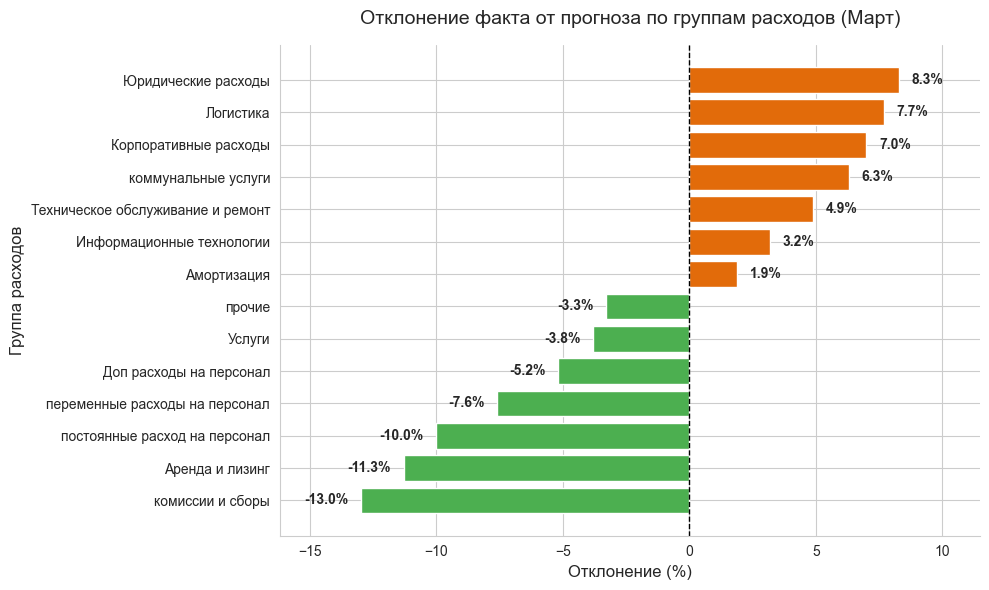

In [22]:
# 1.2.2.1. График отклонений по группам расходов (в %)
# Берем данные для графика (без итоговой строки)
df_plot = df_sheet2_grouped[df_sheet2_grouped['группа расхода'] != 'ИТОГО'].copy()

# Сортируем по проценту отклонения, чтобы на графике был порядок
df_plot = df_plot.sort_values(by=pct_col, ascending=True)

# Создаем фигуру
fig, ax = plt.subplots(figsize=(10, 6))

# Определяем цвета: если отклонение > 0 (перерасход) - оранжевый, иначе - зеленый
colors = ['#E26B0A' if val > 0 else '#4CAF50' for val in df_plot[pct_col]]

# Рисуем горизонтальные столбцы
bars = ax.barh(df_plot['группа расхода'], df_plot[pct_col], color=colors)

# Добавляем вертикальную линию на уровне 0 (базовая линия плана)
ax.axvline(0, color='black', linewidth=1, linestyle='--')

# Добавляем подписи значений (процентов) прямо на столбцах
for bar in bars:
    width = bar.get_width()
    # Если значение положительное, пишем справа от столбца, если отрицательное — слева
    label_x_pos = width + (0.5 if width > 0 else -0.5)
    ha = 'left' if width > 0 else 'right'
    ax.text(label_x_pos, bar.get_y() + bar.get_height()/2, 
            f'{width:.1f}%', 
            va='center', ha=ha, fontsize=10, fontweight='bold')

# Настройка заголовков и осей
ax.set_title(f'Отклонение факта от прогноза по группам расходов ({ACTUAL_MONTH.capitalize()})', fontsize=14, pad=15)
ax.set_xlabel('Отклонение (%)', fontsize=12)
ax.set_ylabel('Группа расходов', fontsize=12)

# --- ИСПРАВЛЕНИЕ ВИЗУАЛЬНОГО НЮАНСА ---
# Находим минимальное и максимальное значение для установки границ оси X с запасом
min_val = df_plot[pct_col].min()
max_val = df_plot[pct_col].max()

# Если разница между макс и мин большая, добавляем 15% запаса с каждой стороны
# Если маленькая (все значения близко к 0), добавляем хотя бы 2% запаса
margin = max((max_val - min_val) * 0.15, 2.0)

ax.set_xlim(min_val - margin, max_val + margin)

# Убираем верхнюю и правую рамки для красоты
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Автоматически подгоняем отступы
plt.tight_layout()

# Сохраняем график в файл (чтобы потом вставить в Excel)
img1_path = os.path.join(DIR_ANALYSIS_FACT, f'график_месяц_{ACTUAL_MONTH}.png')
fig.savefig(img1_path, dpi=150, bbox_inches='tight')
print(f"✅ График сохранен: {img1_path}")

plt.show()


In [41]:
# 1.2.3. Лист 3: Бюджет vs Факт+Прогноз (по месяцам)
## 1. Берем базу
df_sheet3 = df_budget[report_cols].copy()

# 2. Добавляем бюджет по месяцам (сразу)
for m in all_months:
    df_sheet3[f'Бюджет ({m})'] = df_budget[m]

# 3. Добавляем Факт и Прогноз с правильными названиями
for m in all_months:
    if m in closed_months:
        # Для прошедших и текущего месяца — это ФАКТ
        df_sheet3[f'Факт ({m})'] = df_fact_full[m] if m in df_fact_full.columns else 0
    else:
        # Для будущих месяцев — это ПРОГНОЗ
        df_sheet3[f'Прогноз ({m})'] = df_forecast[m]

# 4. Считаем годовые суммы и отклонения
df_sheet3['Бюджет (Год)'] = df_budget[all_months].sum(axis=1)

# Ожидаемый факт = сумма всех "Факт (месяц)" + сумма всех "Прогноз (месяц)"
fact_cols = [f'Факт ({m})' for m in closed_months]
forecast_cols = [f'Прогноз ({m})' for m in future_months]
df_sheet3['Ожидаемый факт (Год)'] = df_sheet3[fact_cols + forecast_cols].sum(axis=1)

df_sheet3['Отклонение (Год)'] = df_sheet3['Ожидаемый факт (Год)'] - df_sheet3['Бюджет (Год)']
df_sheet3['Отклонение % (Год)'] = np.where(
    df_sheet3['Бюджет (Год)'] != 0,
    (df_sheet3['Отклонение (Год)'] / df_sheet3['Бюджет (Год)'] * 100).round(1), 0
)

# 5. Итоговая строка
# Собираем все числовые колонки для суммирования
sum_cols_s3 = (
    [f'Бюджет ({m})' for m in all_months] + 
    fact_cols + forecast_cols + 
    ['Бюджет (Год)', 'Ожидаемый факт (Год)', 'Отклонение (Год)']
)

total_row_s3 = df_sheet3[sum_cols_s3].sum()
total_row_s3['тип расхода'] = 'ИТОГО'
total_row_s3['группа расхода'] = ''
total_row_s3['расход'] = 'ВСЕГО ПО СТАТЬЯМ'
total_row_s3['код статьи'] = ''
total_row_s3['Отклонение % (Год)'] = round((total_row_s3['Отклонение (Год)'] / total_row_s3['Бюджет (Год)'] * 100), 1) if total_row_s3['Бюджет (Год)'] != 0 else 0
df_sheet3 = pd.concat([df_sheet3, pd.DataFrame([total_row_s3])], ignore_index=True)

print("Лист 3 готов. Проверьте названия колонок:")
display(df_sheet3.head(5))
display(df_sheet3.tail(1))

Лист 3 готов. Проверьте названия колонок:


,тип расхода,группа расхода,расход,код статьи,Бюджет (январь),Бюджет (февраль),Бюджет (март),Бюджет (апрель),Бюджет (май),Бюджет (июнь),...,Прогноз (июль),Прогноз (август),Прогноз (сентябрь),Прогноз (октябрь),Прогноз (ноябрь),Прогноз (декабрь),Бюджет (Год),Ожидаемый факт (Год),Отклонение (Год),Отклонение % (Год)
0,переменные,переменные расходы на персонал,Оклад,10101,20000,120000,125000,125000,130000,130000,...,130000,135000,135000,140000,140000,150000,1480000,1475858,-4142,-0.3
1,переменные,переменные расходы на персонал,Ежемесячная премия,10102,15000,15000,16000,16000,17000,17000,...,17000,18000,18000,19000,19000,20000,207000,191355,-15645,-7.6
2,переменные,переменные расходы на персонал,Сверхурочные,10103,5000,4000,6000,5000,7000,6000,...,5000,8000,7000,6000,5000,9000,73000,74619,1619,2.2
3,переменные,переменные расходы на персонал,Налоги на ЗП,10104,36000,36000,37500,37500,39000,39000,...,39000,40500,40500,42000,42000,45000,474000,479135,5135,1.1
4,переменные,переменные расходы на персонал,Бонус,10105,10000,10000,10000,12000,12000,12000,...,15000,15000,15000,18000,18000,20000,167000,155682,-11318,-6.8


,тип расхода,группа расхода,расход,код статьи,Бюджет (январь),Бюджет (февраль),Бюджет (март),Бюджет (апрель),Бюджет (май),Бюджет (июнь),...,Прогноз (июль),Прогноз (август),Прогноз (сентябрь),Прогноз (октябрь),Прогноз (ноябрь),Прогноз (декабрь),Бюджет (Год),Ожидаемый факт (Год),Отклонение (Год),Отклонение % (Год)
84,ИТОГО,,ВСЕГО ПО СТАТЬЯМ,,2124400,2224100,2266100,2276800,2320800,2358500,...,2398000,2362200,2371700,2396900,3223400,2547900,28870800,28630361,-240439,-0.8


In [24]:
# 1.2.4. Лист 4: Сводная таблица Бюджет vs Факт+Прогноз (по группам)
# 1. Берем Лист 3 без строки ИТОГО
df_sheet4 = df_sheet3[df_sheet3['тип расхода'] != 'ИТОГО'].copy()

# 2. Сразу группируем только годовые колонки
# Нам нужны: Бюджет (Год), Ожидаемый факт (Год), Отклонение (Год)
year_cols = ['Бюджет (Год)', 'Ожидаемый факт (Год)', 'Отклонение (Год)']

df_sheet4 = df_sheet4.groupby('группа расхода')[year_cols].sum().reset_index()

# 3. Пересчитываем итоговый процент для сводной
df_sheet4['Отклонение % (Год)'] = np.where(
    df_sheet4['Бюджет (Год)'] != 0,
    (df_sheet4['Отклонение (Год)'] / df_sheet4['Бюджет (Год)'] * 100).round(1), 0
)

# 4. Сортируем по отклонению (перерасход наверху)
df_sheet4 = df_sheet4.sort_values(by='Отклонение (Год)', ascending=False)

# 5. Добавляем итоговую строку
total_row_s4 = df_sheet4[year_cols].sum()
total_row_s4['группа расхода'] = 'ИТОГО'
total_row_s4['Отклонение % (Год)'] = round((total_row_s4['Отклонение (Год)'] / total_row_s4['Бюджет (Год)'] * 100), 1) if total_row_s4['Бюджет (Год)'] != 0 else 0

# Итог в самый конец
df_sheet4 = pd.concat([df_sheet4, pd.DataFrame([total_row_s4])], ignore_index=True)

# 6. Вывод на экран для проверки
print("Сводная таблица по группам (только годовые показатели):")
display(df_sheet4)

Сводная таблица по группам (только годовые показатели):


,группа расхода,Бюджет (Год),Ожидаемый факт (Год),Отклонение (Год),Отклонение % (Год)
0,постоянные расход на персонал,9201000,9210366,9366,0.1
1,Логистика,750000,757796,7796,1.0
2,Доп расходы на персонал,768000,765779,-2221,-0.3
3,Юридические расходы,310000,307641,-2359,-0.8
4,Информационные технологии,1056000,1051864,-4136,-0.4
5,Корпоративные расходы,370000,363342,-6658,-1.8
6,Услуги,1356000,1348790,-7210,-0.5
7,комиссии и сборы,1508000,1500342,-7658,-0.5
8,прочие,1228200,1220119,-8081,-0.7
9,Техническое обслуживание и ремонт,2340000,2319245,-20755,-0.9


✅ График сохранен: Результат\Аналитика\факт\март\график_год_март.png


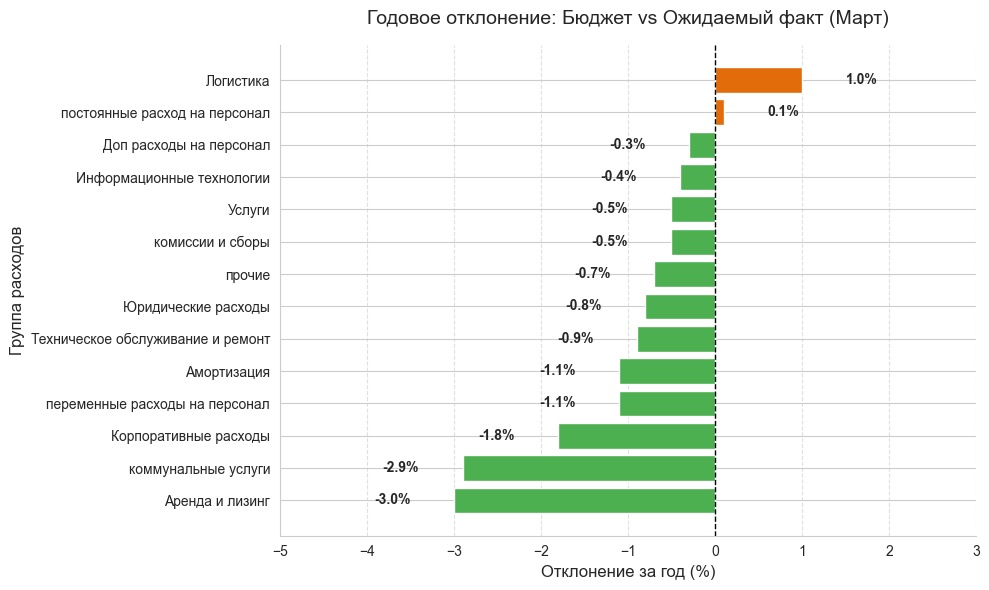

In [25]:
# 1.2.5. График годовых отклонений
df_plot_year = df_sheet4[df_sheet4['группа расхода'] != 'ИТОГО'].copy()
df_plot_year = df_plot_year.sort_values(by='Отклонение % (Год)', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors_year = ['#E26B0A' if val > 0 else '#4CAF50' for val in df_plot_year['Отклонение % (Год)']]

bars = ax.barh(df_plot_year['группа расхода'], df_plot_year['Отклонение % (Год)'], color=colors_year)
ax.axvline(0, color='black', linewidth=1, linestyle='--')

for bar in bars:
    width = bar.get_width()
    label_x_pos = width + (0.5 if width > 0 else -0.5)
    ha = 'left' if width > 0 else 'right'
    ax.text(label_x_pos, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center', ha=ha, fontsize=10, fontweight='bold')

ax.set_title(f'Годовое отклонение: Бюджет vs Ожидаемый факт ({ACTUAL_MONTH.capitalize()})', fontsize=14, pad=15)
ax.set_xlabel('Отклонение за год (%)', fontsize=12)
ax.set_ylabel('Группа расходов', fontsize=12)

# Настройка границ оси X (защита от наезда подписей на края)
min_val = df_plot_year['Отклонение % (Год)'].min()
max_val = df_plot_year['Отклонение % (Год)'].max()
margin = max((max_val - min_val) * 0.15, 2.0)
ax.set_xlim(min_val - margin, max_val + margin)

# Убираем верхнюю и правую рамки для красоты
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Настраиваем сетку по оси X
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Автоматически подгоняем отступы
plt.tight_layout()

# Сохраняем график в файл (img2_path!)
img2_path = os.path.join(DIR_ANALYSIS_FACT, f'график_год_{ACTUAL_MONTH}.png')
fig.savefig(img2_path, dpi=150, bbox_inches='tight')
print(f"✅ График сохранен: {img2_path}")

plt.show()

In [44]:
# записываем данные в файл
# 1. Сохраняем данные (без сдвигов)
with pd.ExcelWriter(OUTPUT_FILE_FACT, engine='openpyxl') as writer:
    df_sheet1.to_excel(writer, sheet_name='1. Факт-Прогноз', index=False)
    df_sheet2_grouped.to_excel(writer, sheet_name='2. Сводная Факт-Прогноз', index=False)
    df_sheet3.to_excel(writer, sheet_name='3. Бюджет vs Факт', index=False)
    df_sheet4.to_excel(writer, sheet_name='4. Сводная Бюджет vs Факт', index=False)

wb = load_workbook(OUTPUT_FILE_FACT)

# Цвета и стили
red_fill = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")
green_fill = PatternFill(start_color="C6EFCE", end_color="C6EFCE", fill_type="solid")
cell_light_blue = PatternFill(start_color="E6F2FF", end_color="E6F2FF", fill_type="solid")
header_bold = Font(bold=True)
center_align = Alignment(horizontal='center', vertical='center', wrap_text=False)

# Лист 1: Факт-Прогноз
ws1 = wb['1. Факт-Прогноз']
ws1.insert_rows(1)

for col in range(1, ws1.max_column + 1):
    cell1 = ws1.cell(row=1, column=col)
    cell1.font = header_bold
    cell1.alignment = center_align
    cell2 = ws1.cell(row=2, column=col)
    
    if col <= 4:
        cell1.value = ""
    elif col in [5, 6, 7]:
        cell1.value = "ФАКТ"
        cell2.value = all_months[col-5].capitalize()
    elif col == 8:
        cell1.value = "ПРОГНОЗ"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif col == 9:
        cell1.value = "ОТКЛОНЕНИЕ (руб)"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif col == 10:
        cell1.value = "ОТКЛОНЕНИЕ (%)"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif col == 11:
        cell1.value = "ПОЯСНЕНИЯ"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif 12 <= col < 12 + len(future_months):
        cell1.value = "ПРОГНОЗ"
        cell2.value = all_months[col-12+3].capitalize()
    else:
        cell1.value = "ИТОГО ЗА ГОД"
        cell2.value = "Год"

ws1.row_dimensions[1].height = 25
for col in range(7, 12):
    for row in range(2, ws1.max_row + 1):
        ws1.cell(row=row, column=col).fill = cell_light_blue

for row in range(3, ws1.max_row + 1):
    cell = ws1.cell(row=row, column=10)
    if isinstance(cell.value, (int, float)):
        if cell.value > 10: cell.fill = red_fill
        elif cell.value < -10: cell.fill = green_fill

# Лист 2: Сводная Факт-Прогноз
ws2 = wb['2. Сводная Факт-Прогноз']
ws2.insert_rows(1)

for col in range(1, ws2.max_column + 1):
    cell1 = ws2.cell(row=1, column=col)
    cell1.font = header_bold
    cell1.alignment = center_align
    cell2 = ws2.cell(row=2, column=col)
    
    if col == 1:
        cell1.value = ""
    elif col in [2, 3, 4]:
        cell1.value = "ФАКТ"
        cell2.value = all_months[col-2].capitalize()
    elif col == 5:
        cell1.value = "ПРОГНОЗ"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif col == 6:
        cell1.value = "ОТКЛОНЕНИЕ (руб)"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif col == 7:
        cell1.value = "ОТКЛОНЕНИЕ (%)"
        cell2.value = ACTUAL_MONTH.capitalize()
    elif 8 <= col < 8 + len(future_months):
        cell1.value = "ПРОГНОЗ"
        cell2.value = all_months[col-8+3].capitalize()
    else:
        cell1.value = "ИТОГО ЗА ГОД"
        cell2.value = "Год"

ws2.row_dimensions[1].height = 25
for col in range(4, 8):
    for row in range(2, ws2.max_row + 1):
        ws2.cell(row=row, column=col).fill = cell_light_blue

for row in range(3, ws2.max_row + 1):
    cell = ws2.cell(row=row, column=7)
    if isinstance(cell.value, (int, float)):
        if cell.value > 10: cell.fill = red_fill
        elif cell.value < -10: cell.fill = green_fill

# Лист 3: Бюджет vs Факт
ws3 = wb['3. Бюджет vs Факт']
ws3.insert_rows(1)

for col in range(1, ws3.max_column + 1):
    cell1 = ws3.cell(row=1, column=col)
    cell1.font = header_bold
    cell1.alignment = center_align
    cell2 = ws3.cell(row=2, column=col)
    
    if col <= 4:
        cell1.value = ""
    elif 5 <= col <= 16: # 12 колонок бюджета
        cell1.value = "БЮДЖЕТ"
        cell2.value = all_months[col-5].capitalize()
    elif 17 <= col <= 28: # 12 колонок факта/прогноза
        month_index = col - 17
        if month_index < current_month_num:
            cell1.value = "ФАКТ"
        else:
            cell1.value = "ПРОГНОЗ"
        cell2.value = all_months[month_index].capitalize()
    elif col == 29:
        cell1.value = "БЮДЖЕТ (ГОД)"
        cell2.value = "Год"
    elif col == 30:
        cell1.value = "ФАКТ + ПРОГНОЗ (ГОД)"
        cell2.value = "Год"
    elif col == 31:
        cell1.value = "ОТКЛОНЕНИЕ (РУБ)"
        cell2.value = "Год"
    elif col == 32:
        cell1.value = "ОТКЛОНЕНИЕ (%)"
        cell2.value = "Год"
    elif col == 33:
        cell1.value = "ПОЯСНЕНИЯ"
        cell2.value = "Год"

ws3.row_dimensions[1].height = 25

for row in range(3, ws3.max_row + 1):
    cell_pct = ws3.cell(row=row, column=32)
    if isinstance(cell_pct.value, (int, float)):
        if cell_pct.value > 10: cell_pct.fill = red_fill
        elif cell_pct.value < -10: cell_pct.fill = green_fill

# Автоширина
def set_auto_width(ws):
    for col in range(1, ws.max_column + 1):
        max_len = 0
        for row in range(1, ws.max_row + 1):
            cell = ws.cell(row=row, column=col)
            if cell.value:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[get_column_letter(col)].width = min(max(max_len + 3, 10), 50)

for sheet_name in ['1. Факт-Прогноз', '2. Сводная Факт-Прогноз', '3. Бюджет vs Факт']:
    set_auto_width(wb[sheet_name])

for sheet_name in ['1. Факт-Прогноз', '3. Бюджет vs Факт', '4. Сводная Бюджет vs Факт']:
    ws = wb[sheet_name]
    for col in range(1, ws.max_column + 1):
        val = str(ws.cell(row=2 if sheet_name != '4. Сводная Бюджет vs Факт' else 1, column=col).value).lower()
        if val in ['расход', 'группа расхода']:
            ws.column_dimensions[get_column_letter(col)].width = 40

# Лист 4: Сводная Бюджет vs Факт
ws4 = wb['4. Сводная Бюджет vs Факт']
for col in range(1, ws4.max_column + 1):
    ws4.cell(row=1, column=col).font = header_bold
set_auto_width(ws4)
ws4.column_dimensions['A'].width = 40

# Вставка графиков
if os.path.exists(img1_path):
    ws_graph1 = wb.create_sheet('5. График (Месяц)')
    img1 = XLImage(img1_path)
    ws_graph1.add_image(img1, 'B2')

if os.path.exists(img2_path):
    ws_graph2 = wb.create_sheet('6. График (Год)')
    img2 = XLImage(img2_path)
    ws_graph2.add_image(img2, 'B2')

wb.save(OUTPUT_FILE_FACT)
print(f"✅ Отчет сохранен!")

✅ Отчет сохранен!


### 1.3. Создание таблиц для каждого бюджетодержателя

In [56]:
# 1. Подготовка данных
df_budget = pd.read_excel(PATH_BUDGET, sheet_name='Бюджет')
df_for_holders = df_sheet1[df_sheet1['тип расхода'] != 'ИТОГО'].copy()

df_budget['код статьи'] = df_budget['код статьи'].astype(str).str.strip()
df_for_holders['код статьи'] = df_for_holders['код статьи'].astype(str).str.strip()

df_for_holders = pd.merge(df_for_holders, df_budget[['код статьи', 'бюджетодержатель']], on='код статьи', how='left')

# 2. Стили
yellow_fill = PatternFill(start_color="FFF2CC", end_color="FFF2CC", fill_type="solid")
blue_fill = PatternFill(start_color="DDEBF7", end_color="DDEBF7", fill_type="solid")
red_fill = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")
green_fill = PatternFill(start_color="C6EFCE", end_color="C6EFCE", fill_type="solid")
header_font = Font(bold=True)
center_align = Alignment(horizontal='center', vertical='center')

holders = df_for_holders['бюджетодержатель'].dropna().unique()
count = 0

for holder in holders:
    df_holder = df_for_holders[df_for_holders['бюджетодержатель'] == holder]
    safe_name = "".join([c for c in holder if c.isalnum() or c in (' ', '_', '-')]).strip()
    file_path = os.path.join(DIR_HOLDERS_SEND, f'{safe_name}_{ACTUAL_MONTH}.xlsx')
    
    with pd.ExcelWriter(file_path, engine='openpyxl') as writer:
        # --- ЛИСТ 2: Факт vs Прогноз ---
        cols_fact = ['расход', 'код статьи', f'Прогноз ({ACTUAL_MONTH})', ACTUAL_MONTH, 
                     f'Отклонение ({ACTUAL_MONTH})', f'Отклонение % ({ACTUAL_MONTH})', f'Пояснения ({ACTUAL_MONTH})']
        df_fact = df_holder[cols_fact].copy()
        df_fact.rename(columns={ACTUAL_MONTH: f'Факт ({ACTUAL_MONTH})', f'Пояснения ({ACTUAL_MONTH})': 'Комментарий по факту'}, inplace=True)
        df_fact.to_excel(writer, sheet_name='2. Факт vs Прогноз', index=False)

        # --- ЛИСТ 3: Обновление прогноза ---
        future_forecast_cols = [m for m in future_months if m in df_holder.columns]
        df_forecast = df_holder[['расход', 'код статьи'] + future_forecast_cols].copy()
        df_forecast['Причина изменения прогноза'] = ""
        df_forecast.to_excel(writer, sheet_name='3. Обновление прогноза', index=False)
        
        # --- ЛИСТ 4: Сводка по году ---
        df_summary = df_holder[['расход', 'код статьи']].copy()
        
        budget_year_series = df_budget.loc[df_budget['код статьи'].isin(df_holder['код статьи']), all_months].sum(axis=1)
        df_summary['Бюджет (Год)'] = budget_year_series.values
        
        fact_closed = df_holder[[m for m in closed_months if m in df_holder.columns]].sum(axis=1)
        forecast_old = df_holder[future_forecast_cols].sum(axis=1)
        df_summary['Факт + Прогноз (Старый)'] = fact_closed.values + forecast_old.values
        df_summary['Отклонение (Старый)'] = df_summary['Факт + Прогноз (Старый)'] - df_summary['Бюджет (Год)']
        
        # Оставляем пустые ячейки для формул
        df_summary['Факт + Прогноз (Новый)'] = None
        df_summary['Отклонение (Новый)'] = None
        df_summary['Эффект от корректировки (Dif-Dif)'] = None
        
        # Сохраняем факт_closed во временную колонку (потом скроем)
        df_summary['_Факт'] = fact_closed.values
        
        df_summary.to_excel(writer, sheet_name='4. Сводка по году', index=False, startrow=1)

    # --- НАСТРОЙКА ЛИСТОВ И ВСТАВКА ФОРМУЛ ---
    wb = load_workbook(file_path)
    
    ws3 = wb['3. Обновление прогноза']
    ws4 = wb['4. Сводка по году']
    
    # 1. Находим индексы нужных колонок на Листе 4
    col_dict = {}
    for col in range(1, ws4.max_column + 1):
        val = str(ws4.cell(row=2, column=col).value)
        if val: col_dict[val] = col
        
    col_hidden_fact = ws4.max_column
    col_new_prog = col_dict.get('Факт + Прогноз (Новый)')
    col_dev_new = col_dict.get('Отклонение (Новый)')
    col_dif_dif = col_dict.get('Эффект от корректировки (Dif-Dif)')
    col_budget = col_dict.get('Бюджет (Год)')
    col_dev_old = col_dict.get('Отклонение (Старый)')

    # Находим последнюю колонку с месяцем на Листе 3
    last_month_col_letter = 'C'
    for col in range(1, ws3.max_column + 1):
        if 'причина' in str(ws3.cell(row=1, column=col).value).lower():
            last_month_col_letter = get_column_letter(col - 1)
            break

    # 2. Вставляем формулы
    if col_new_prog:
        for row in range(3, ws4.max_row + 1):
            row_str = str(row)
            
            # Новый прогноз = СкрытыйФакт + Сумма(Новый прогноз с Листа 3)
            formula_new = f"={get_column_letter(col_hidden_fact)}{row_str} + SUM('3. Обновление прогноза'!C{row_str}:{last_month_col_letter}{row_str})"
            ws4.cell(row=row, column=col_new_prog).value = formula_new
            
            # Отклонение (Новый) = Новый прогноз - Бюджет
            formula_dev = f"={get_column_letter(col_new_prog)}{row_str} - {get_column_letter(col_budget)}{row_str}"
            ws4.cell(row=row, column=col_dev_new).value = formula_dev
            
            # Dif-Dif = Отклонение (Новый) - Отклонение (Старый)
            formula_dif = f"={get_column_letter(col_dev_new)}{row_str} - {get_column_letter(col_dev_old)}{row_str}"
            ws4.cell(row=row, column=col_dif_dif).value = formula_dif

    # 3. Скрываем колонку с фактом (пользователю она не нужна)
    ws4.column_dimensions[get_column_letter(col_hidden_fact)].hidden = True

    # ЛИСТ 1: ИНСТРУКЦИЯ
    ws_inst = wb.create_sheet('1. Инструкция', 0)
    ws_inst.sheet_view.showGridLines = False
    ws_inst.column_dimensions['B'].width = 100
    ws_inst['B2'] = "ИНСТРУКЦИЯ ПО ЗАПОЛНЕНИЮ ОТЧЕТА"
    ws_inst['B2'].font = Font(size=16, bold=True, color="1F4E78")
    
    instructions = [
        "Уважаемый бюджетодержатель!",
        "",
        "Вам необходимо заполнить желтые и голубые ячейки на листах 2 и 3.",
        "",
        "ЛИСТ 2 'ФАКТ VS ПРОГНОЗ':",
        "1. Ознакомьтесь с фактом за текущий месяц.",
        "2. В крайней правой колонке (голубой фон) напишите причину отклонения факта.",
        "",
        "ЛИСТ 3 'ОБНОВЛЕНИЕ ПРОГНОЗА':",
        "1. Пересмотрите прогноз на будущие месяцы (до конца года).",
        "2. Впишите новые суммы в желтые ячейки.",
        "3. В крайней правой колонке объясните, почему прогноз изменился.",
        "",
        "ЛИСТ 4 'СВОДКА ПО ГОДУ':",
        "Здесь автоматически формируется годовой итог. Как только вы измените цифры на Листе 3, итоги на Листе 4 пересчитаются автоматически.",
        "",
        "Обратите внимание: остальные колонки защищены от редактирования."
    ]
    for i, text in enumerate(instructions):
        ws_inst.cell(row=4+i, column=2).value = text
        ws_inst.cell(row=4+i, column=2).alignment = Alignment(wrap_text=True, vertical='top')
        if text.endswith(":"):
            ws_inst.cell(row=4+i, column=2).font = Font(bold=True)

    # ЛИСТ 2: Оформление
    ws_fact = wb['2. Факт vs Прогноз']
    ws_fact.insert_rows(1)
    for col in range(1, ws_fact.max_column + 1):
        ws_fact.cell(row=1, column=col).font = header_font
        ws_fact.cell(row=1, column=col).alignment = center_align
    
    for row in range(2, ws_fact.max_row + 1):
        ws_fact.cell(row=row, column=ws_fact.max_column).fill = blue_fill
        cell = ws_fact.cell(row=row, column=6)
        if isinstance(cell.value, (int, float)):
            if cell.value > 10: cell.fill = red_fill
            elif cell.value < -10: cell.fill = green_fill

    # ЛИСТ 3: Оформление и подсветка
    ws_forecast = wb['3. Обновление прогноза']
    ws_forecast.insert_rows(1)
    for col in range(1, ws_forecast.max_column + 1):
        ws_forecast.cell(row=1, column=col).font = header_font
        ws_forecast.cell(row=1, column=col).alignment = center_align
        
        header_val = str(ws_forecast.cell(row=2, column=col).value).lower()
        if any(m in header_val for m in future_months) or 'причина' in header_val:
            for row in range(2, ws_forecast.max_row + 1):
                ws_forecast.cell(row=row, column=col).fill = yellow_fill

    # ЛИСТ 4: Оформление заголовков
    ws4.cell(row=1, column=1).value = "ИТОГОВАЯ СВОДКА ПО ГОДУ"
    ws4.cell(row=1, column=1).font = Font(size=14, bold=True)
    ws4.merge_cells(start_row=1, start_column=1, end_row=1, end_column=9)
    
    for col in range(1, ws4.max_column + 1):
        ws4.cell(row=2, column=col).font = header_font
        ws4.cell(row=2, column=col).alignment = center_align

    # ЗАЩИТА И АВТОШИРИНА
    for sheet_name in wb.sheetnames:
        ws = wb[sheet_name]
        
        if sheet_name in ['1. Инструкция', '4. Сводка по году']:
            ws.protection.sheet = True
            continue
            
        for row in ws.iter_rows():
            for cell in row:
                cell.protection = Protection(locked=False)
        
        for row in range(1, ws.max_row + 1):
            for col in range(1, ws.max_column + 1):
                cell = ws.cell(row=row, column=col)
                header_val = str(ws.cell(row=2, column=col).value).lower()
                
                is_editable = False
                if sheet_name == '2. Факт vs Прогноз' and 'комментарий' in header_val:
                    is_editable = True
                elif sheet_name == '3. Обновление прогноза' and (any(m in header_val for m in future_months) or 'причина' in header_val):
                    is_editable = True
                    
                if not is_editable:
                    cell.protection = Protection(locked=True)
                    
        ws.protection.sheet = True

    # ЕДИНАЯ АВТОШИРИНА
    for sheet_name in wb.sheetnames:
        ws = wb[sheet_name]
        for col in range(1, ws.max_column + 1):
            max_len = 0
            for row in range(1, ws.max_row + 1):
                cell = ws.cell(row=row, column=col)
                if cell.value:
                    max_len = max(max_len, len(str(cell.value)))
            ws.column_dimensions[get_column_letter(col)].width = min(max(max_len + 3, 12), 45)
        
        for col in range(1, 4):
            if str(ws.cell(row=2 if sheet_name != '4. Сводка по году' else 2, column=col).value).lower() == 'расход':
                ws.column_dimensions[get_column_letter(col)].width = 40

    wb.save(file_path)
    count += 1

print(f"✅ Создано {count} файлов с 4 листами и работающими формулами.")

✅ Создано 8 файлов с 4 листами и работающими формулами.
